# TMDB 5000: quick EDA

A short exploratory pass over the TMDB movies and credits files: merge them, inspect missing values, focus on movies with reported budget and revenue, then look at financial relationships, genres, and directors. The original audit notebook remains available as `01_exploratory_data_analysis.ipynb`.


In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT.parent / "data"
movies = pd.read_csv(DATA_DIR / "tmdb_5000_movies.csv")
credits = pd.read_csv(DATA_DIR / "tmdb_5000_credits.csv")


## 1. Merge and inspect

Join on the shared movie ID and remove the repeated credits title. The missing-value summary is a quick overview of blank fields in the merged data.


In [3]:
df = movies.merge(
    credits,
    left_on="id",
    right_on="movie_id",
    how="inner",
    suffixes=("", "_credits"),
)
df = df.drop(columns=["movie_id", "title_credits"])

print(f"Merged rows and columns: {df.shape}")
df.isnull().sum().sort_values(ascending=False).to_frame("missing values")


Merged rows and columns: (4803, 22)


,missing values
homepage,3091
tagline,844
overview,3
runtime,2
release_date,1
budget,0
original_language,0
keywords,0
id,0
genres,0


## 2. Keep reported financials and reduce skew

Zero budget or revenue values are treated as unreported for this exploratory view. This filter defines the analysis subset; it does not say why a value was absent. `log1p` makes large differences easier to see while retaining zero-safe behavior.


In [4]:
df["budget"] = pd.to_numeric(df["budget"], errors="coerce")
df["revenue"] = pd.to_numeric(df["revenue"], errors="coerce")
financial = df.loc[
    df["budget"].gt(0) & df["revenue"].gt(0),
].copy()
financial["log_budget"] = np.log1p(financial["budget"])
financial["log_revenue"] = np.log1p(financial["revenue"])

print(f"Movies with positive budget and revenue: {len(financial):,} of {len(df):,}")
print(financial[["budget", "revenue", "log_budget", "log_revenue"]].describe().round(2))


Movies with positive budget and revenue: 3,229 of 4,803
             budget       revenue  log_budget  log_revenue
count  3.229000e+03  3.229000e+03     3229.00      3229.00
mean   4.065444e+07  1.212430e+08       16.80        17.49
std    4.439674e+07  1.863029e+08        1.66         2.08
min    1.000000e+00  5.000000e+00        0.69         1.79
25%    1.050000e+07  1.700000e+07       16.17        16.65
50%    2.500000e+07  5.518472e+07       17.03        17.83
75%    5.500000e+07  1.462920e+08       17.82        18.80
max    3.800000e+08  2.787965e+09       19.76        21.75


## 3. Explore relationships

The scatterplot compares log budget and revenue for the filtered subset. The correlation matrix includes the transformed financial fields plus popularity and average vote. Correlation is descriptive and does not imply a causal effect.


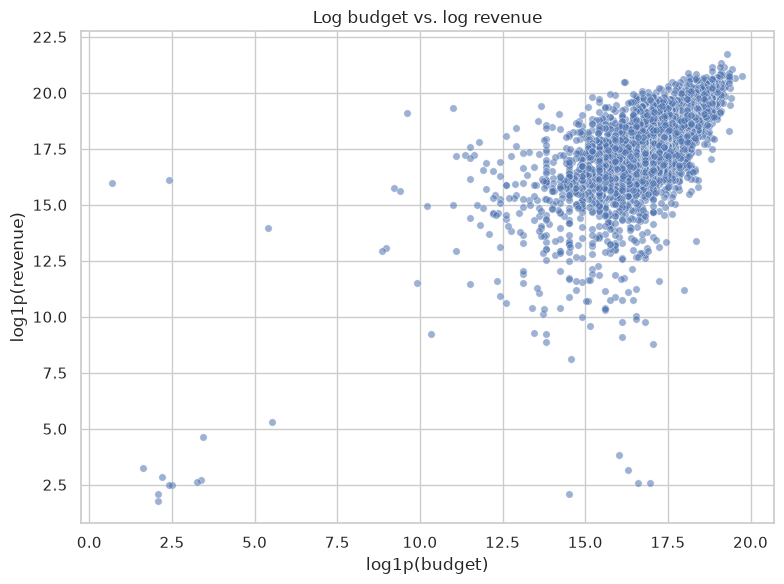

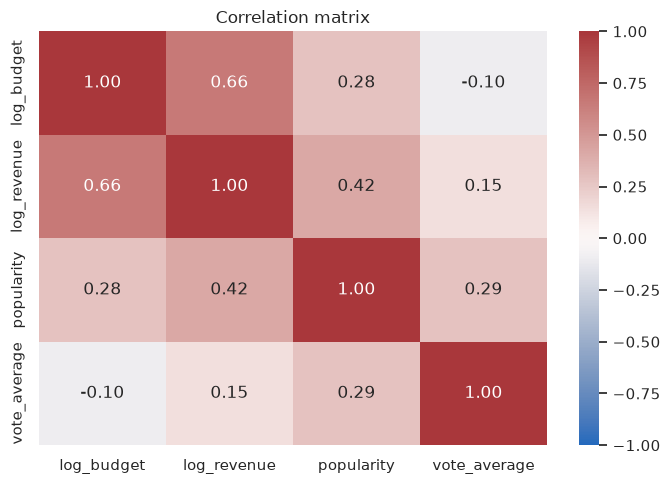

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=financial, x="log_budget", y="log_revenue",
    alpha=0.55, s=28, ax=ax,
)
ax.set(title="Log budget vs. log revenue", xlabel="log1p(budget)", ylabel="log1p(revenue)")
plt.tight_layout()
plt.show()

corr_cols = ["log_budget", "log_revenue", "popularity", "vote_average"]
correlations = financial[corr_cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()


## 4. Most common genres and directors

Genres are multi-label, so one movie can count under several genres. Directors are extracted from the credits JSON; rows without a parsed director are grouped as `Unknown`.


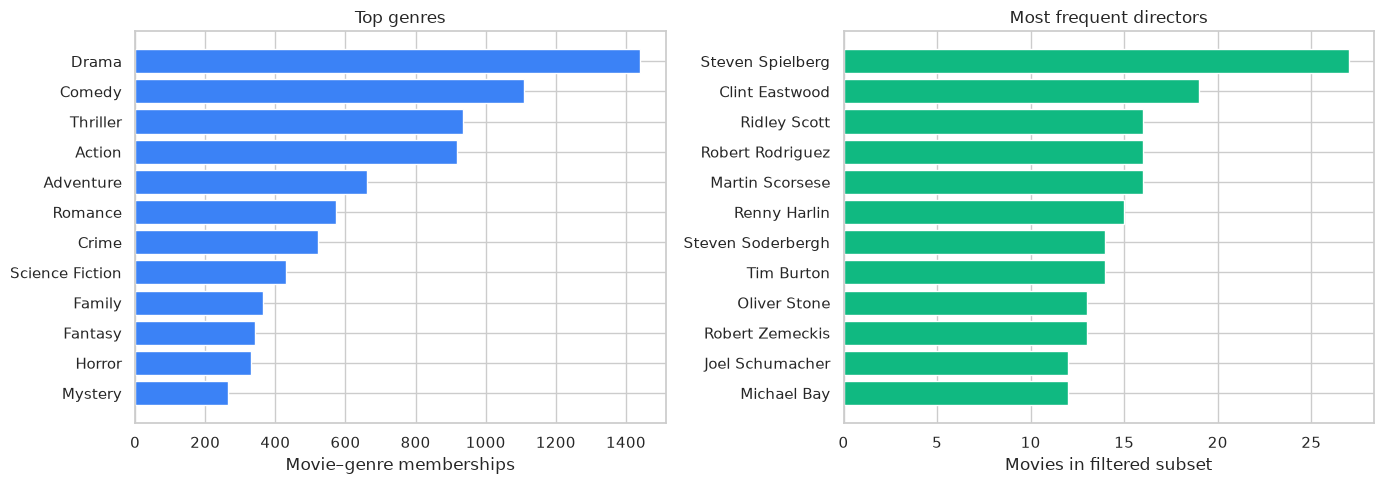

In [6]:
def parse_names(blob):
    try:
        return [item["name"] for item in json.loads(blob)]
    except (TypeError, ValueError, KeyError):
        return []

genre_counts = pd.Series(
    [name for names in financial["genres"].apply(parse_names) for name in names]
).value_counts().head(12).sort_values()

def director_name(blob):
    try:
        crew = json.loads(blob)
        return next((person.get("name", "Unknown") for person in crew
                     if person.get("job") == "Director"), "Unknown")
    except (TypeError, ValueError):
        return "Unknown"

director_counts = financial["crew"].apply(director_name).value_counts()
director_counts = director_counts.drop(index="Unknown", errors="ignore").head(12).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(genre_counts.index, genre_counts.values, color="#3b82f6")
axes[0].set_title("Top genres")
axes[0].set_xlabel("Movie–genre memberships")
axes[1].barh(director_counts.index, director_counts.values, color="#10b981")
axes[1].set_title("Most frequent directors")
axes[1].set_xlabel("Movies in filtered subset")
plt.tight_layout()
plt.show()
